In [1]:
%pip install -q netmedpy networkx pandas numpy scipy matplotlib

In [2]:
import os
import pickle
import urllib.request
import networkx as nx
import numpy as np
import pandas as pd
import netmedpy
import random

print("All libraries imported successfully!")
print("NetMedPy version:", __import__("importlib").metadata.version("netmedpy"))

All libraries imported successfully!
NetMedPy version: 0.2.0.1


In [3]:
os.makedirs("data", exist_ok=True)

base = "https://raw.githubusercontent.com/menicgiulia/NetMedPy/master/examples/VitaminD/data/input/"

files = {
    "ppi_network.pkl": base + "ppi/ppi_network.pkl",
    "vitd_targets_cpie.pkl": base + "drug_targets/vitd_targets_cpie.pkl",
    "disease_genes_merge.pkl": base + "disease_genes/disease_genes_merge.pkl"
}

for name, url in files.items():
    urllib.request.urlretrieve(url, f"data/{name}")
    print("Downloaded:", name)

print("All datasets downloaded successfully!")

Downloaded: ppi_network.pkl
Downloaded: vitd_targets_cpie.pkl
Downloaded: disease_genes_merge.pkl
All datasets downloaded successfully!


In [4]:
with open("data/ppi_network.pkl", "rb") as f:
    ppi_network = pickle.load(f)

with open("data/vitd_targets_cpie.pkl", "rb") as f:
    vitd_targets = pickle.load(f)

with open("data/disease_genes_merge.pkl", "rb") as f:
    disease_genes = pickle.load(f)

print("PPI network:", ppi_network.number_of_nodes(), "proteins")
print("Interactions:", ppi_network.number_of_edges())
print("Vitamin D targets:", len(vitd_targets))
print("Disease datasets:", len(disease_genes))
print("Datasets loaded successfully!")

PPI network: 18642 proteins
Interactions: 354650
Vitamin D targets: 16
Disease datasets: 13
Datasets loaded successfully!


In [5]:
print("DISEASE GENE COVERAGE\n")

coverage = []

for disease, genes in disease_genes.items():
    genes = set(genes)
    present = genes & set(ppi_network.nodes())

    coverage.append({
        "Disease": disease,
        "Total genes": len(genes),
        "Genes in network": len(present),
        "Coverage (%)": round(len(present) / len(genes) * 100, 2)
    })

coverage_df = pd.DataFrame(coverage)
coverage_df = coverage_df.sort_values(
    "Genes in network", ascending=False
)

display(coverage_df)

DISEASE GENE COVERAGE



,Disease,Total genes,Genes in network,Coverage (%)
1,Asthma,1695,1531,90.32
2,CAD,1089,986,90.54
0,Inflammation,632,608,96.20
5,COPD,515,481,93.40
3,Vitamin D Def,80,78,97.50
8,Prader-Willi Syn,79,63,79.75
11,Fragile X Syn,67,60,89.55
6,Rett Syn,53,52,98.11
7,Rickets,48,45,93.75
12,Factor IX Def,44,43,97.73


In [6]:
drug_targets = set(vitd_targets) & set(ppi_network.nodes())

selected_disease = "Inflammation"

disease_targets = (
    set(disease_genes[selected_disease])
    & set(ppi_network.nodes())
)

print("Drug: Vitamin D")
print("Drug targets:", len(drug_targets))
print("Disease:", selected_disease)
print("Disease genes:", len(disease_targets))
print("Network nodes:", ppi_network.number_of_nodes())
print("Network connected:", nx.is_connected(ppi_network))

Drug: Vitamin D
Drug targets: 15
Disease: Inflammation
Disease genes: 608
Network nodes: 18642
Network connected: True


In [7]:
minimum_distances = []

for target in drug_targets:
    distances = nx.single_source_shortest_path_length(
        ppi_network, target
    )

    nearest = min(distances[gene] for gene in disease_targets)
    minimum_distances.append(nearest)

observed_proximity = np.mean(minimum_distances)

print("Observed proximity:", round(observed_proximity, 4))
print("Drug targets analysed:", len(minimum_distances))

Observed proximity: 0.4
Drug targets analysed: 15


In [8]:
import random
import numpy as np

random.seed(42)
n_iter = 100

degree_groups = {}

for node in ppi_network:
    degree_groups.setdefault(ppi_network.degree(node), []).append(node)

def degree_matched_sample(nodes):
    return {
        random.choice(degree_groups[ppi_network.degree(node)])
        for node in nodes
    }

random_proximities = []

for i in range(n_iter):
    random_drugs = degree_matched_sample(drug_targets)
    random_disease = degree_matched_sample(disease_targets)

    minimums = []

    for target in random_drugs:
        distances = nx.single_source_shortest_path_length(
            ppi_network, target
        )
        minimums.append(min(distances[g] for g in random_disease))

    random_proximities.append(np.mean(minimums))

random_proximities = np.array(random_proximities)

z_score = (
    observed_proximity - random_proximities.mean()
) / random_proximities.std()

p_value = (
    np.sum(random_proximities <= observed_proximity) + 1
) / (n_iter + 1)

print("Observed proximity:", observed_proximity)
print("Random mean:", random_proximities.mean())
print("Z-score:", z_score)
print("Empirical p-value:", p_value)

Observed proximity: 0.4
Random mean: 1.3484285714285715
Z-score: -9.173364018323285
Empirical p-value: 0.009900990099009901


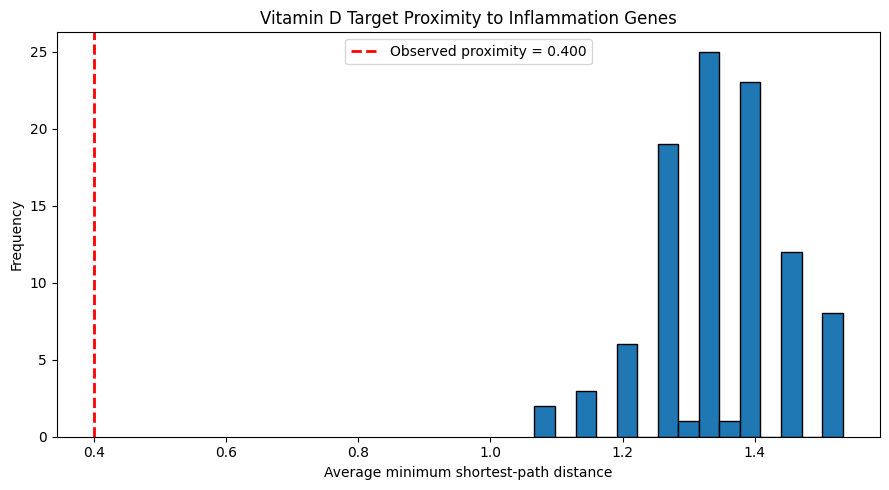

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(random_proximities, bins=15, edgecolor="black")
plt.axvline(
    observed_proximity,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Observed proximity = {observed_proximity:.3f}"
)

plt.xlabel("Average minimum shortest-path distance")
plt.ylabel("Frequency")
plt.title("Vitamin D Target Proximity to Inflammation Genes")
plt.legend()
plt.tight_layout()
plt.savefig("proximity_results.png", dpi=300)
plt.show()

In [10]:
results = pd.DataFrame({
    "Metric": [
        "Drug",
        "Disease",
        "Drug targets",
        "Disease genes",
        "Observed proximity",
        "Random mean proximity",
        "Z-score",
        "Empirical p-value",
        "Random iterations"
    ],
    "Value": [
        "Vitamin D",
        selected_disease,
        len(drug_targets),
        len(disease_targets),
        observed_proximity,
        random_proximities.mean(),
        z_score,
        p_value,
        n_iter
    ]
})

display(results)

results.to_csv("proximity_results.csv", index=False)
print("Results saved successfully!")

,Metric,Value
0,Drug,Vitamin D
1,Disease,Inflammation
2,Drug targets,15
3,Disease genes,608
4,Observed proximity,0.4
5,Random mean proximity,1.348429
6,Z-score,-9.173364
7,Empirical p-value,0.009901
8,Random iterations,100


Results saved successfully!


In [11]:
import random
import numpy as np

random.seed(42)
n_iter = 100

# Use NetMedPy's degree-matched null model
helpers = netmedpy.proximity.__globals__

bucket = helpers["_degree_match_null_model"](ppi_network)
sample_function = helpers["_sample_preserving_degrees"]

random_proximities = []

for i in range(n_iter):

    random_drugs = sample_function(ppi_network, drug_targets, bucket)
    random_disease = sample_function(ppi_network, disease_targets, bucket)

    # Calculate distance to the nearest disease protein
    distances = nx.multi_source_dijkstra_path_length(
        ppi_network,
        sources=random_disease,
        weight=None
    )

    random_proximities.append(
        np.mean([distances[node] for node in random_drugs])
    )

random_proximities = np.array(random_proximities)

z_score = (
    observed_proximity - np.mean(random_proximities)
) / np.std(random_proximities)

p_value = (
    np.sum(random_proximities <= observed_proximity) + 1
) / (n_iter + 1)

print("Observed proximity:", round(observed_proximity, 4))
print("Degree-matched random mean:", round(random_proximities.mean(), 4))
print("Z-score:", round(z_score, 4))
print("Empirical p-value:", round(p_value, 4))
print("Iterations:", n_iter)

Observed proximity: 0.4
Degree-matched random mean: 1.344
Z-score: -7.9226
Empirical p-value: 0.0099
Iterations: 100


In [13]:
readme = f"""
# Network-Based Drug Repurposing

## Research Question
Are Vitamin D drug targets located close to inflammation-associated
proteins in a human protein-protein interaction network?

## Dataset
NetMedPy VitaminD example dataset:
https://github.com/menicgiulia/NetMedPy

- PPI proteins: {ppi_network.number_of_nodes()}
- PPI interactions: {ppi_network.number_of_edges()}
- Vitamin D targets: {len(drug_targets)}
- Inflammation genes: {len(disease_targets)}

## Method
Network-based proximity analysis using average minimum
shortest-path distance.

Statistical significance was evaluated using NetMedPy's
degree-matched null-model sampling with 100 iterations.

## Modification Beyond the Tutorial
We selected Inflammation from the available disease gene sets
and investigated its proximity to Vitamin D drug targets.
This changes the biological comparison from the tutorial example.

## Results and Interpretation

- Observed proximity: {observed_proximity:.4f}
- Degree-matched random mean: {np.mean(random_proximities):.4f}
- Z-score: {z_score:.4f}
- Empirical p-value: {p_value:.4f}
- Random iterations: {n_iter}

The observed proximity is lower than the degree-matched random
mean. The negative z-score indicates that Vitamin D targets are
closer to inflammation-associated proteins than expected under
the degree-matched random comparison.

This suggests a network-level association, not proof that
Vitamin D is an effective treatment for inflammation.

## Limitations
- Protein interaction networks are incomplete.
- Network proximity does not establish clinical effectiveness.
- The analysis uses 100 random iterations.
- The disease gene set may contain heterogeneous biological roles.

## How to Run
1. Install dependencies using requirements.txt.
2. Run python download_data.py to download datasets.
3. Open the analysis notebook in Google Colab or Jupyter.
4. Run the notebook cells in order.

## Files
- requirements.txt: Python dependencies
- download_data.py: Dataset download script
- proximity_results.csv: Statistical results
- proximity_results.png: Results graph
"""

with open("README.md", "w") as f:
    f.write(readme)

print("README updated with corrected statistical results!")

README updated with corrected statistical results!


In [14]:
disease_comparison = []

for disease, genes in disease_genes.items():

    genes = set(genes) & set(ppi_network.nodes())

    if not genes:
        continue

    minimums = []

    for target in drug_targets:
        distances = nx.single_source_shortest_path_length(
            ppi_network, target
        )
        minimums.append(min(distances[g] for g in genes))

    disease_comparison.append({
        "Disease": disease,
        "Genes in network": len(genes),
        "Observed proximity": np.mean(minimums)
    })

comparison_df = pd.DataFrame(disease_comparison)

comparison_df = comparison_df.sort_values(
    "Observed proximity"
).reset_index(drop=True)

display(comparison_df)

comparison_df.to_csv("all_disease_comparison.csv", index=False)

print("Comparison across diseases completed!")

,Disease,Genes in network,Observed proximity
0,Inflammation,608,0.400000
1,Asthma,1531,0.533333
2,CAD,986,0.600000
3,COPD,481,1.066667
4,Vitamin D Def,78,1.266667
5,Rickets,45,1.600000
6,Brain Neoplasms,42,1.666667
7,Rett Syn,52,1.733333
8,Prader-Willi Syn,63,1.733333
9,Fragile X Syn,60,1.800000


Comparison across diseases completed!


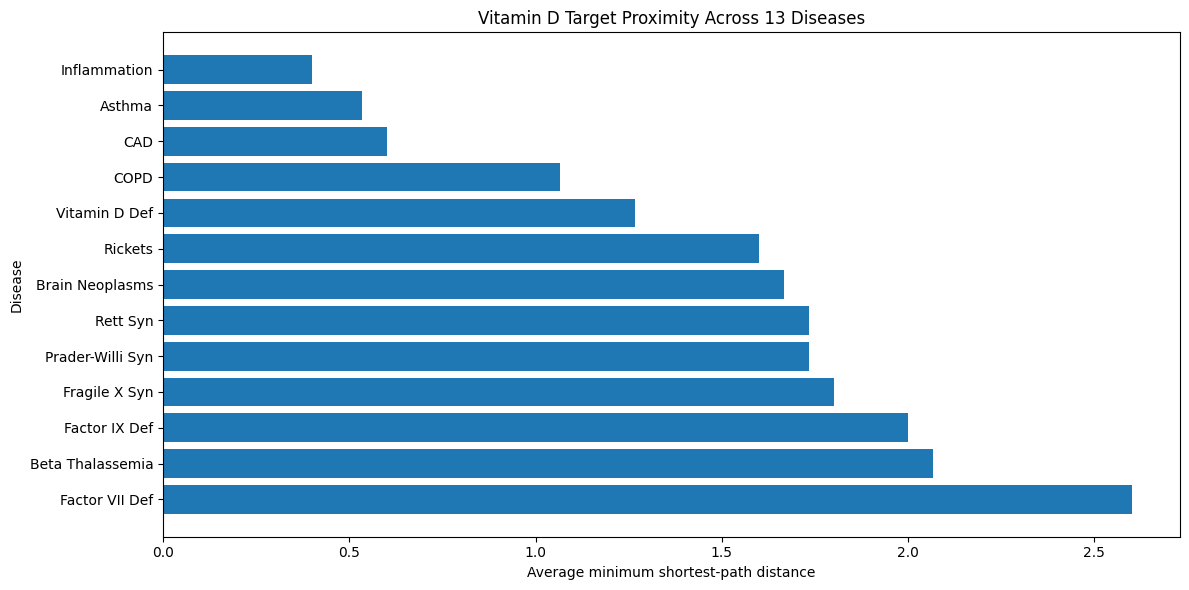

Disease comparison graph saved!


In [15]:
plt.figure(figsize=(12, 6))

plt.barh(
    comparison_df["Disease"],
    comparison_df["Observed proximity"]
)

plt.xlabel("Average minimum shortest-path distance")
plt.ylabel("Disease")
plt.title("Vitamin D Target Proximity Across 13 Diseases")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig("all_disease_comparison.png", dpi=300)
plt.show()

print("Disease comparison graph saved!")

In [16]:
print("FINAL RESULTS AND INTERPRETATION")
print("=" * 50)

print(f"""
1. The closest disease to Vitamin D targets is:
   {comparison_df.iloc[0]['Disease']}

2. Its observed proximity is:
   {comparison_df.iloc[0]['Observed proximity']:.4f}

3. Inflammation has {len(disease_targets)} genes in the network.

4. Vitamin D has {len(drug_targets)} targets in the network.

5. The observed Inflammation proximity is {observed_proximity:.4f},
   compared with a degree-matched random mean of
   {np.mean(random_proximities):.4f}.

6. The Z-score is {z_score:.4f} and the empirical p-value is
   {p_value:.4f}.

CONCLUSION:
Vitamin D targets show close network proximity to
inflammation-associated proteins in this PPI network.
Inflammation has the lowest observed proximity among the
13 disease gene sets examined.

This suggests a potential network-level association.
It does not prove that Vitamin D is an effective treatment
for inflammation.
""")

FINAL RESULTS AND INTERPRETATION

1. The closest disease to Vitamin D targets is:
   Inflammation

2. Its observed proximity is:
   0.4000

3. Inflammation has 608 genes in the network.

4. Vitamin D has 15 targets in the network.

5. The observed Inflammation proximity is 0.4000,
   compared with a degree-matched random mean of
   1.3440.

6. The Z-score is -7.9226 and the empirical p-value is
   0.0099.

CONCLUSION:
Vitamin D targets show close network proximity to
inflammation-associated proteins in this PPI network.
Inflammation has the lowest observed proximity among the
13 disease gene sets examined.

This suggests a potential network-level association.
It does not prove that Vitamin D is an effective treatment
for inflammation.



In [18]:
# Create requirements.txt
with open("requirements.txt", "w") as f:
    f.write("""netmedpy==0.2.0.1
networkx
numpy
pandas
scipy
matplotlib
""")

# Create download_data.py
download_code = '''import os
import urllib.request

os.makedirs("data", exist_ok=True)

base = "https://raw.githubusercontent.com/menicgiulia/NetMedPy/master/examples/VitaminD/data/input/"

files = {
    "ppi_network.pkl": base + "ppi/ppi_network.pkl",
    "vitd_targets_cpie.pkl": base + "drug_targets/vitd_targets_cpie.pkl",
    "disease_genes_merge.pkl": base + "disease_genes/disease_genes_merge.pkl"
}

for filename, url in files.items():
    urllib.request.urlretrieve(url, f"data/{filename}")
    print("Downloaded:", filename)

print("All datasets downloaded successfully!")
'''

with open("download_data.py", "w") as f:
    f.write(download_code)

print("Created requirements.txt")
print("Created download_data.py")
print("Files ready for download!")

Created requirements.txt
Created download_data.py
Files ready for download!
